# Data Ingestion, Cleaning & Preprocessing with Pandas

**Dataset:** Retail sales transactions (Jan 2023 – Dec 2025), 11,300 raw rows × 13 columns  
**Goal:** Take a messy, real-world business dataset with missing values, duplicate records and inconsistent data types, and turn it into a clean, analysis-ready file.

| Step | What we do |
|---|---|
| 1 | Load the raw data into Pandas |
| 2 | Audit the problems (**before** cleaning) |
| 3 | Standardise text labels and fix data types |
| 4 | Remove duplicates |
| 5 | Detect and handle outliers |
| 6 | Handle missing values |
| 7 | Feature engineering (month / year, revenue, profit margin, …) |
| 8 | Validate, compare **before vs after**, export `clean_dataset.csv` |

**Column guide:** `order_id`, `order_date`, `ship_date`, `customer_id`, `customer_name`, `region`, `category`, `product_name`, `quantity`, `unit_price` (₹), `cost_price` (₹), `discount_pct` (%), `payment_method`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 160)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
print("pandas", pd.__version__)

pandas 3.0.5


## 1. Load the raw dataset
Everything is read as-is (no type coercion), so we can see exactly how messy the source file is.

In [2]:
df_raw = pd.read_csv("raw_retail_sales.csv")
orig_cols = list(df_raw.columns)
print(f"Rows: {df_raw.shape[0]:,} | Columns: {df_raw.shape[1]}")
df_raw.head(10)

Rows: 11,300 | Columns: 13


,order_id,order_date,ship_date,customer_id,customer_name,region,category,product_name,quantity,unit_price,cost_price,discount_pct,payment_method
0,100090,06/30/2025,2025/07/02,2677,Naveen Singh,NORTH,Clothing,Cotton Kurta,1.0,1156.83,651.92,10.0,UPI
1,110292,03/07/2025,10/07/2025,1969,KARTHIK SINGH,Central,Grocery,Green Tea Box,five,402.89,246.49,0.0,CC
2,109327,2023/06/28,04-Jul-2023,1503,MEERA PILLAI,EAST,BEAUTY,Moisturizer,1.0,₹609.90,290.03,15.0,Debit Card
3,107764,28/09/2025,2025/10/06,2615,Lakshmi Patel,South,Beauty,Perfume,3.0,"₹1,828.38",858.54,0.0,UPI
4,100093,10/07/2025,2025/07/19,1620,Lakshmi Rao,Central,Home & Kitchen,Mixer Grinder,6.0,4480.42,"₹2,757.76",20%,UPI
5,108343,2023-08-08,17/08/2023,2053,Pooja Patel,east,Clothing,Denim Jeans,5.0,2170.24,1314.37,5.0,Net Banking
6,102547,05/20/2025,05/26/2025,2987,Lakshmi Rao,Central,Electronics,Smart Watch,3 units,5987.22,4309.98,25.0,Credit Card
7,105015,22/12/2024,NaN,2165,Nisha Sharma,East,Clothing,Formal Shirt,2.0,1743.06,949.22,0%,Debit Card
8,103434,2024/01/04,2024-01-10,2183,DEEPAK PATEL,north,Electronics,Bluetooth Speaker,2.0,3082.87,2054.66,10.0,Net banking
9,109466,11/01/2024,2024-01-12,3169,Arjun Rao,Central,Home & Kitchen,Mixer Grinder,7.0,4265.76,2935.12,25.0,Upi


In [3]:
df_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 11300 entries, 0 to 11299
Data columns (total 13 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   order_id        11300 non-null  int64
 1   order_date      11291 non-null  str  
 2   ship_date       10962 non-null  str  
 3   customer_id     10768 non-null  str  
 4   customer_name   10843 non-null  str  
 5   region          10725 non-null  str  
 6   category        11185 non-null  str  
 7   product_name    11300 non-null  str  
 8   quantity        10960 non-null  str  
 9   unit_price      10940 non-null  str  
 10  cost_price      10839 non-null  str  
 11  discount_pct    10629 non-null  str  
 12  payment_method  10735 non-null  str  
dtypes: int64(1), str(12)
memory usage: 1.1 MB


**Observation:** `quantity`, `unit_price`, `cost_price`, `discount_pct`, `customer_id`, `order_date` and `ship_date` are all stored as generic text (`object` / `str`) even though they should be numbers and dates.

## 2. Audit the data (BEFORE cleaning)
First some reusable helpers: a column profiler, a parser for mixed date formats, and a function that scores data quality so we can compare before vs after at the end.

**Date assumption:** slash dates are read as `dd/mm/YYYY` first. If that is impossible (e.g. month = 30) the value is re-read as `mm/dd/YYYY`.

In [4]:
DATE_FORMATS = ["%Y-%m-%d", "%Y/%m/%d", "%d-%b-%Y", "%d/%m/%Y", "%m/%d/%Y"]  # order matters: dd/mm before mm/dd

def parse_mixed_dates(s):
    """Parse a column with several date formats; unparseable values become NaT."""
    s = s.astype("string").str.strip()
    out = pd.Series(pd.NaT, index=s.index, dtype="datetime64[ns]")
    for fmt in DATE_FORMATS:
        out = out.fillna(pd.to_datetime(s, format=fmt, errors="coerce").astype("datetime64[ns]"))
    return out

def profile(d):
    return pd.DataFrame({
        "dtype": d.dtypes.astype(str),
        "missing": d.isna().sum(),
        "missing_%": (d.isna().mean() * 100).round(2),
        "unique": d.nunique(),
    })

NUM_COLS  = ["customer_id", "quantity", "unit_price", "cost_price", "discount_pct"]
DATE_COLS = ["order_date", "ship_date"]

def quality_metrics(d):
    d = d[orig_cols]
    text_in_numeric = sum(((pd.to_numeric(d[c], errors="coerce").isna()) & d[c].notna()).sum() for c in NUM_COLS)
    bad_dates = sum(parse_mixed_dates(d[c]).isna().sum() - d[c].isna().sum() for c in DATE_COLS)
    wrong_dtype = sum(not pd.api.types.is_numeric_dtype(d[c]) for c in NUM_COLS) + \
                  sum(not pd.api.types.is_datetime64_any_dtype(d[c]) for c in DATE_COLS)
    return {
        "Rows": len(d),
        "Exact duplicate rows": int(d.duplicated().sum()),
        "Duplicate order_id values": int(d["order_id"].duplicated().sum()),
        "Missing cells (NaN)": int(d.isna().sum().sum()),
        "Unparseable / placeholder dates": int(bad_dates),
        "Text values inside numeric columns": int(text_in_numeric),
        "Columns with wrong dtype (of 7)": int(wrong_dtype),
        "Distinct region labels": int(d["region"].nunique()),
        "Distinct category labels": int(d["category"].nunique()),
        "Distinct payment labels": int(d["payment_method"].nunique()),
    }

prof_before = profile(df_raw)
prof_before

,dtype,missing,missing_%,unique
order_id,int64,0,0.00,10500
order_date,str,9,0.08,4358
ship_date,str,338,2.99,4346
customer_id,str,532,4.71,2205
customer_name,str,457,4.04,945
region,str,575,5.09,30
category,str,115,1.02,21
product_name,str,0,0.00,25
quantity,str,340,3.01,28
unit_price,str,360,3.19,10067


In [5]:
before = quality_metrics(df_raw)
print(pd.Series(before, name="BEFORE").to_string())
print("\nRegion labels  :", sorted(df_raw["region"].dropna().unique())[:18])
print("Payment labels :", sorted(df_raw["payment_method"].dropna().unique()))
print("Order-date samples:", df_raw["order_date"].dropna().sample(6, random_state=1).tolist())
print("Unit-price samples:", df_raw["unit_price"].dropna().sample(6, random_state=2).tolist())

Rows                                  11300
Exact duplicate rows                    762
Duplicate order_id values               800
Missing cells (NaN)                    4423
Unparseable / placeholder dates          22
Text values inside numeric columns     8383
Columns with wrong dtype (of 7)           7
Distinct region labels                   30
Distinct category labels                 21
Distinct payment labels                  18

Region labels  : [' Central ', ' East ', ' North ', ' South ', ' West ', 'C.', 'CENTRAL', 'Central', 'E.', 'EAST', 'East', 'N.', 'NORTH', 'North', 'S.', 'SOUTH', 'South', 'W.']
Payment labels : ['CC', 'COD', 'Cash On Delivery', 'Cash on Delivery', 'Credit Card', 'Credit-Card', 'DC', 'Debit Card', 'Gpay/UPI', 'Net Banking', 'Net banking', 'UPI', 'Upi', 'cod', 'credit card', 'debit card', 'netbanking', 'upi']
Order-date samples: ['2023-10-27', '2024-09-18', '06-Mar-2024', '2023-03-10', '25-Jan-2025', '04/04/2024']
Unit-price samples: ['448.05', '4128.91',

### Problems found
- **Missing values** in 11 columns (up to ~6% each) plus placeholder dates such as `N/A` and impossible dates such as `31/02/2024`.
- **Duplicates:** exact copies *and* near-copies (same `order_id`, different name casing).
- **Inconsistent types:** prices with `₹`, `Rs.` and commas; quantities like `3 units` or `five`; discounts as `10%`, `10` and `0.1`; customer IDs like `C2677`.
- **Inconsistent labels:** `South`, `south`, `SOUTH`, ` S. `; `COD`, `Cash on Delivery`; `Home & Kitchen` vs `home and kitchen`.
- **Outliers:** quantities of 250–999 and prices 10–50× higher than normal.

## 3. Standardise text labels
Whitespace, casing and abbreviations are fixed **first**, so that later steps (duplicate detection, grouping) treat identical values as identical.

In [6]:
df = df_raw.copy()

# --- names: trim, collapse spaces, Title Case
df["customer_name"] = (df["customer_name"].astype("string").str.strip()
                         .str.replace(r"\s+", " ", regex=True).str.title())

# --- region: abbreviations and casing -> 5 canonical values
region_map = {"north": "North", "n": "North", "south": "South", "s": "South", "east": "East", "e": "East",
              "west": "West", "w": "West", "central": "Central", "c": "Central"}
df["region"] = df["region"].astype("string").str.strip().str.lower().str.rstrip(".").map(region_map)

# --- category: "home and kitchen" / "HOME & KITCHEN" -> "Home & Kitchen"
df["category"] = (df["category"].astype("string").str.strip().str.lower()
                    .str.replace(" and ", " & ", regex=False).str.title())

# --- payment method: abbreviations -> 5 canonical values
pay_map = {"credit card": "Credit Card", "credit-card": "Credit Card", "cc": "Credit Card",
           "debit card": "Debit Card", "dc": "Debit Card",
           "upi": "UPI", "gpay/upi": "UPI",
           "cash on delivery": "Cash on Delivery", "cod": "Cash on Delivery",
           "net banking": "Net Banking", "netbanking": "Net Banking"}
df["payment_method"] = df["payment_method"].astype("string").str.strip().str.lower().map(pay_map)

df["product_name"] = df["product_name"].astype("string").str.strip()

# nothing should have fallen through the maps (original NaN stays NaN, anything else would be a bug)
assert df["region"].isna().sum() == df_raw["region"].isna().sum()
assert df["payment_method"].isna().sum() == df_raw["payment_method"].isna().sum()
assert df["category"].isna().sum() == df_raw["category"].isna().sum()

for c in ["region", "category", "payment_method"]:
    print(f"{c:15s}", sorted(df[c].dropna().unique()))

region          ['Central', 'East', 'North', 'South', 'West']
category        ['Beauty', 'Clothing', 'Electronics', 'Grocery', 'Home & Kitchen']
payment_method  ['Cash on Delivery', 'Credit Card', 'Debit Card', 'Net Banking', 'UPI']


## 4. Fix incorrect data types
Each numeric column is converted with an explicit rule, and a check confirms that **no valid value was lost** in the conversion (the number of NaNs must not grow).

In [7]:
def assert_no_new_nulls(new, old, name):
    extra = int(new.isna().sum() - old.isna().sum())
    assert extra == 0, f"{name}: {extra} values failed to convert"
    print(f"{name:14s} -> {str(new.dtype):8s} (values lost in conversion: {extra})")

# prices: strip "₹", "Rs." and thousands separators
for c in ["unit_price", "cost_price"]:
    cleaned = df[c].astype("string").str.replace(r"[₹,]|Rs\.", "", regex=True).str.strip()
    df[c] = pd.to_numeric(cleaned, errors="coerce")
    assert_no_new_nulls(df[c], df_raw[c], c)

# quantity: "3 units" -> 3, "five" -> 5
word_map = {"one": "1", "two": "2", "three": "3", "four": "4", "five": "5"}
q = (df["quantity"].astype("string").str.strip().str.lower()
       .str.replace(r"\s*units?$", "", regex=True).replace(word_map))
df["quantity"] = pd.to_numeric(q, errors="coerce")
assert_no_new_nulls(df["quantity"], df_raw["quantity"], "quantity")

# discount: "10%" -> 10, 0.1 -> 10, 10.0 -> 10   (everything expressed as a percentage 0-100)
d = df["discount_pct"].astype("string").str.strip()
had_pct = d.str.contains("%", na=False)
v = pd.to_numeric(d.str.replace("%", "", regex=False), errors="coerce")
v = v.where(had_pct | (v == 0) | (v >= 1), v * 100).round(2)
df["discount_pct"] = v
assert_no_new_nulls(df["discount_pct"], df_raw["discount_pct"], "discount_pct")
assert df["discount_pct"].dropna().between(0, 100).all()

# customer id: "C2677" -> 2677 (nullable integer keeps real gaps as <NA>)
cid = df["customer_id"].astype("string").str.replace("C", "", regex=False).str.strip()
df["customer_id"] = pd.to_numeric(cid, errors="coerce").astype("Int64")
assert_no_new_nulls(df["customer_id"], df_raw["customer_id"], "customer_id")

# dates: five different formats -> datetime64; placeholders / impossible dates -> NaT
for c in DATE_COLS:
    df[c] = parse_mixed_dates(df[c])
print("order_date unparseable (will be handled below):", int(df["order_date"].isna().sum() - df_raw["order_date"].isna().sum()))
df.dtypes

unit_price     -> Float64  (values lost in conversion: 0)
cost_price     -> Float64  (values lost in conversion: 0)
quantity       -> Float64  (values lost in conversion: 0)
discount_pct   -> Float64  (values lost in conversion: 0)
customer_id    -> Int64    (values lost in conversion: 0)


order_date unparseable (will be handled below): 22


order_id                   int64
order_date        datetime64[ns]
ship_date         datetime64[ns]
customer_id                Int64
customer_name             string
region                       str
category                  string
product_name              string
quantity                 Float64
unit_price               Float64
cost_price               Float64
discount_pct             Float64
payment_method               str
dtype: object

## 5. Remove duplicate records
Duplicates are removed **after** standardising text and types. Before that, a row like `KARTHIK SINGH / ₹1,828.38` and its copy `Karthik Singh / 1828.38` look different even though they are the same order.

1. Drop exact duplicate rows.
2. `order_id` is a unique key, so any remaining repeated `order_id` is also a duplicate. Keep the most complete record.

In [8]:
n0 = len(df)
exact = int(df.duplicated().sum())
df = df.drop_duplicates()

df = (df.assign(_filled=df.notna().sum(axis=1))
        .sort_values(["order_id", "_filled"], ascending=[True, False])
        .drop_duplicates("order_id", keep="first")
        .drop(columns="_filled")
        .reset_index(drop=True))

print(f"Rows before: {n0:,}")
print(f"Exact duplicates removed (after standardising): {exact:,}")
print(f"Extra same-order_id duplicates removed: {n0 - exact - len(df):,}")
print(f"Rows after : {len(df):,}   | order_id unique: {df['order_id'].is_unique}")

Rows before: 11,300
Exact duplicates removed (after standardising): 800
Extra same-order_id duplicates removed: 0
Rows after : 10,500   | order_id unique: True


## 6. Detect and handle outliers
**Method:** IQR rule *within each product* (a ₹6,000 smart watch is normal, a ₹6,000 USB-C cable is not). A value is an outlier if it lies beyond `Q1 − 1.5·IQR` or `Q3 + 1.5·IQR`; non-positive values are also invalid.  
**Treatment:** outliers are almost certainly entry errors (e.g. 999 units, price ×50), so they are set to missing and re-estimated with the product median in the next step. Rows are kept, because the rest of the order is valid.

In [9]:
def iqr_outliers(frame, col, by="product_name", k=1.5):
    g = frame.groupby(by)[col]
    q1, q3 = g.transform(lambda s: s.quantile(0.25)), g.transform(lambda s: s.quantile(0.75))
    iqr = q3 - q1
    return (frame[col] < q1 - k * iqr) | (frame[col] > q3 + k * iqr) | (frame[col] <= 0)

outlier_counts = {}
for col in ["unit_price", "cost_price", "quantity"]:
    mask = iqr_outliers(df, col)
    outlier_counts[col] = int(mask.sum())
    if col != "cost_price":
        ex = df.loc[mask, ["order_id", "product_name", col]].head(4)
        med = df.groupby("product_name")[col].median()
        ex = ex.assign(product_median=ex["product_name"].map(med))
        print(f"\n{col}: {mask.sum()} outliers - examples")
        print(ex.to_string(index=False))
    df[f"{col}_outlier"] = mask          # temporary marker, used for the imputation flags below
    df.loc[mask, col] = np.nan

print("\nOutliers set to missing:", outlier_counts)


unit_price: 41 outliers - examples
 order_id      product_name  unit_price  product_median
   100113      Cotton Kurta   62,824.00        1,197.47
   100173 Bluetooth Speaker  158,541.00        3,204.81
   100601      Formal Shirt   17,565.00        1,808.70
   100907       Smart Watch  141,867.50        5,976.97

quantity: 40 outliers - examples
 order_id  product_name  quantity  product_median
   101155 Running Shoes    250.00            4.00
   101440  Cotton Kurta    500.00            4.00
   101627  Cotton Kurta    999.00            4.00
   101788    Silk Saree    999.00            4.00

Outliers set to missing: {'unit_price': 41, 'cost_price': 0, 'quantity': 40}


## 7. Handle missing values
| Column | Strategy | Why |
|---|---|---|
| `order_date` | Drop the row | The key date cannot be guessed; only a handful of rows |
| `ship_date` | `order_date` + median shipping lag (also fixes any ship date earlier than the order date) | Shipping time is stable |
| `category` | Look up from `product_name` | Each product belongs to exactly one category |
| `unit_price`, `cost_price`, `quantity` | Median of the same product (includes the outliers removed above) | Robust to extreme values |
| `discount_pct` | 0 | No recorded discount means no discount |
| `customer_name`, `region`, `payment_method` | `"Unknown"` | Categorical, no honest estimate exists |
| `customer_id` | Left as `<NA>` | An ID must never be invented |

Boolean `*_imputed` flag columns record exactly which values were estimated, so analysts can filter them out if needed.

In [10]:
print("Missing values before imputation:")
print(df[orig_cols].isna().sum()[lambda s: s > 0].to_string())

# 1) rows without a usable order date
n_before = len(df)
df = df.dropna(subset=["order_date"]).reset_index(drop=True)
print(f"\nDropped rows with missing/invalid order_date: {n_before - len(df)}")

# 2) ship date: impossible (before order) -> missing, then fill with median lag
df.loc[df["ship_date"] < df["order_date"], "ship_date"] = pd.NaT
median_lag = int((df["ship_date"] - df["order_date"]).dt.days.median())
df["ship_date_imputed"] = df["ship_date"].isna()
df["ship_date"] = df["ship_date"].fillna(df["order_date"] + pd.to_timedelta(median_lag, unit="D"))

# 3) category from product
prod_cat = df.dropna(subset=["category"]).groupby("product_name")["category"].agg(lambda s: s.mode().iat[0])
df["category"] = df["category"].fillna(df["product_name"].map(prod_cat))

# 4) numeric columns: product median, with a flag column
for col in ["unit_price", "cost_price", "quantity"]:
    df[f"{col}_imputed"] = df[col].isna()
    df[col] = df[col].fillna(df.groupby("product_name")[col].transform("median"))
df["quantity"] = df["quantity"].round().astype("int64")
df = df.drop(columns=["unit_price_outlier", "cost_price_outlier", "quantity_outlier"])

# 5) discount and categorical placeholders
df["discount_pct"] = df["discount_pct"].fillna(0)
for col in ["customer_name", "region", "payment_method"]:
    df[col] = df[col].fillna("Unknown")

print("\nMissing values after imputation:")
print(df[orig_cols].isna().sum()[lambda s: s > 0].to_string(), "(customer_id is intentionally left blank)")
print("Median shipping lag used:", median_lag, "days")

Missing values before imputation:
order_date         31
ship_date         315
customer_id       494
customer_name     420
region            525
category          105
quantity          355
unit_price        377
cost_price        420
discount_pct      630
payment_method    525

Dropped rows with missing/invalid order_date: 31

Missing values after imputation:
customer_id    489 (customer_id is intentionally left blank)
Median shipping lag used: 5 days


## 8. Feature engineering
New columns for analysis:

- **Date features:** `order_year`, `order_month`, `month_name`, `quarter`, `day_of_week`, `is_weekend`, `ship_lag_days`
- **Money features:** `gross_sales`, `discount_amount`, `revenue`, `total_cost`, `profit`, `profit_margin_pct`

`revenue = quantity × unit_price × (1 − discount)` and `profit_margin_pct = profit ÷ revenue × 100`.

In [11]:
# date features
df["order_year"]    = df["order_date"].dt.year
df["order_month"]   = df["order_date"].dt.month
df["month_name"]    = df["order_date"].dt.month_name()
df["quarter"]       = "Q" + df["order_date"].dt.quarter.astype(str)
df["day_of_week"]   = df["order_date"].dt.day_name()
df["is_weekend"]    = df["order_date"].dt.dayofweek >= 5
df["ship_lag_days"] = (df["ship_date"] - df["order_date"]).dt.days

# money features
df["gross_sales"]       = (df["quantity"] * df["unit_price"]).round(2)
df["discount_amount"]   = (df["gross_sales"] * df["discount_pct"] / 100).round(2)
df["revenue"]           = (df["gross_sales"] - df["discount_amount"]).round(2)
df["total_cost"]        = (df["quantity"] * df["cost_price"]).round(2)
df["profit"]            = (df["revenue"] - df["total_cost"]).round(2)
df["profit_margin_pct"] = (df["profit"] / df["revenue"] * 100).round(2)

# tidy: sensible column order, sorted by date, rounded prices
df["unit_price"] = df["unit_price"].round(2)
df["cost_price"] = df["cost_price"].round(2)
df_clean = df.sort_values(["order_date", "order_id"]).reset_index(drop=True)
df_clean = df_clean[orig_cols + [c for c in df_clean.columns if c not in orig_cols]]

df_clean[["order_id", "order_date", "product_name", "quantity", "unit_price", "discount_pct",
          "revenue", "profit", "profit_margin_pct", "order_year", "month_name", "quarter"]].head(8)

,order_id,order_date,product_name,quantity,unit_price,discount_pct,revenue,profit,profit_margin_pct,order_year,month_name,quarter
0,102316,2023-01-01,Formal Shirt,5,"1,901.76",0.00,"9,508.80","4,623.40",48.62,2023,January,Q1
1,103674,2023-01-01,Green Tea Box,5,402.87,5.00,"1,913.63",650.08,33.97,2023,January,Q1
2,105083,2023-01-01,Formal Shirt,5,"1,724.45",10.00,"7,760.03","3,161.73",40.74,2023,January,Q1
3,106302,2023-01-01,Water Bottle,3,528.26,5.00,"1,505.54",861.77,57.24,2023,January,Q1
4,107006,2023-01-01,Basmati Rice 5kg,3,761.33,0.00,"2,283.99",535.35,23.44,2023,January,Q1
5,108283,2023-01-01,Running Shoes,7,"3,370.81",5.00,"22,415.89","6,828.43",30.46,2023,January,Q1
6,101409,2023-01-02,Denim Jeans,7,"2,149.27",0.00,"15,044.89","5,922.42",39.36,2023,January,Q1
7,101482,2023-01-02,Silk Saree,5,"8,865.16",0.00,"44,325.80","17,690.10",39.91,2023,January,Q1


In [12]:
summary = (df_clean.groupby("category")
           .agg(orders=("order_id", "count"), revenue=("revenue", "sum"),
                profit=("profit", "sum"), avg_margin_pct=("profit_margin_pct", "mean"))
           .sort_values("revenue", ascending=False))
summary["revenue"] = summary["revenue"].round(0)
summary["profit"] = summary["profit"].round(0)
summary

,orders,revenue,profit,avg_margin_pct
category,,,,
Clothing,2652,"33,825,233.00","10,707,023.00",34.45
Electronics,2583,"25,751,250.00","6,665,655.00",30.44
Home & Kitchen,2039,"17,234,648.00","5,347,144.00",34.70
Beauty,1675,"4,696,816.00","2,234,176.00",48.59
Grocery,1520,"3,676,266.00","812,811.00",22.66


## 9. Validate the cleaned data
Automated checks: if any one fails, the notebook stops, so the exported file is guaranteed to meet these rules.

In [13]:
checks = {
    "No duplicate rows":                         not df_clean.duplicated().any(),
    "order_id is unique":                        df_clean["order_id"].is_unique,
    "10,000+ rows retained":                     len(df_clean) >= 10_000,
    "No missing values except customer_id":      df_clean.drop(columns="customer_id").isna().sum().sum() == 0,
    "Dates are datetime64":                      all(pd.api.types.is_datetime64_any_dtype(df_clean[c]) for c in DATE_COLS),
    "Numeric columns are numeric":               all(pd.api.types.is_numeric_dtype(df_clean[c]) for c in NUM_COLS),
    "ship_date >= order_date":                   (df_clean["ship_date"] >= df_clean["order_date"]).all(),
    "Quantity between 1 and 20":                 df_clean["quantity"].between(1, 20).all(),
    "Prices positive":                           (df_clean[["unit_price", "cost_price"]] > 0).all().all(),
    "Discount between 0 and 100":                df_clean["discount_pct"].between(0, 100).all(),
    "Region has 5 values + Unknown":             set(df_clean["region"]) <= {"North", "South", "East", "West", "Central", "Unknown"},
    "Revenue = gross - discount":                np.allclose(df_clean["revenue"], df_clean["gross_sales"] - df_clean["discount_amount"]),
    "No infinite margins":                       np.isfinite(df_clean["profit_margin_pct"]).all(),
}
for name, ok in checks.items():
    print(("PASS" if ok else "FAIL"), "-", name)
assert all(checks.values()), "Validation failed"
print(f"\nAll {len(checks)} checks passed.")

PASS - No duplicate rows
PASS - order_id is unique
PASS - 10,000+ rows retained
PASS - No missing values except customer_id
PASS - Dates are datetime64
PASS - Numeric columns are numeric
PASS - ship_date >= order_date
PASS - Quantity between 1 and 20
PASS - Prices positive
PASS - Discount between 0 and 100
PASS - Region has 5 values + Unknown
PASS - Revenue = gross - discount
PASS - No infinite margins

All 13 checks passed.


## 10. Before vs After

In [14]:
after = quality_metrics(df_clean)
comparison = pd.DataFrame({"Before": before, "After": after})
comparison["Change"] = comparison["After"] - comparison["Before"]
comparison

,Before,After,Change
Rows,11300,10469,-831
Exact duplicate rows,762,0,-762
Duplicate order_id values,800,0,-800
Missing cells (NaN),4423,489,-3934
Unparseable / placeholder dates,22,0,-22
Text values inside numeric columns,8383,0,-8383
Columns with wrong dtype (of 7),7,0,-7
Distinct region labels,30,6,-24
Distinct category labels,21,5,-16
Distinct payment labels,18,6,-12


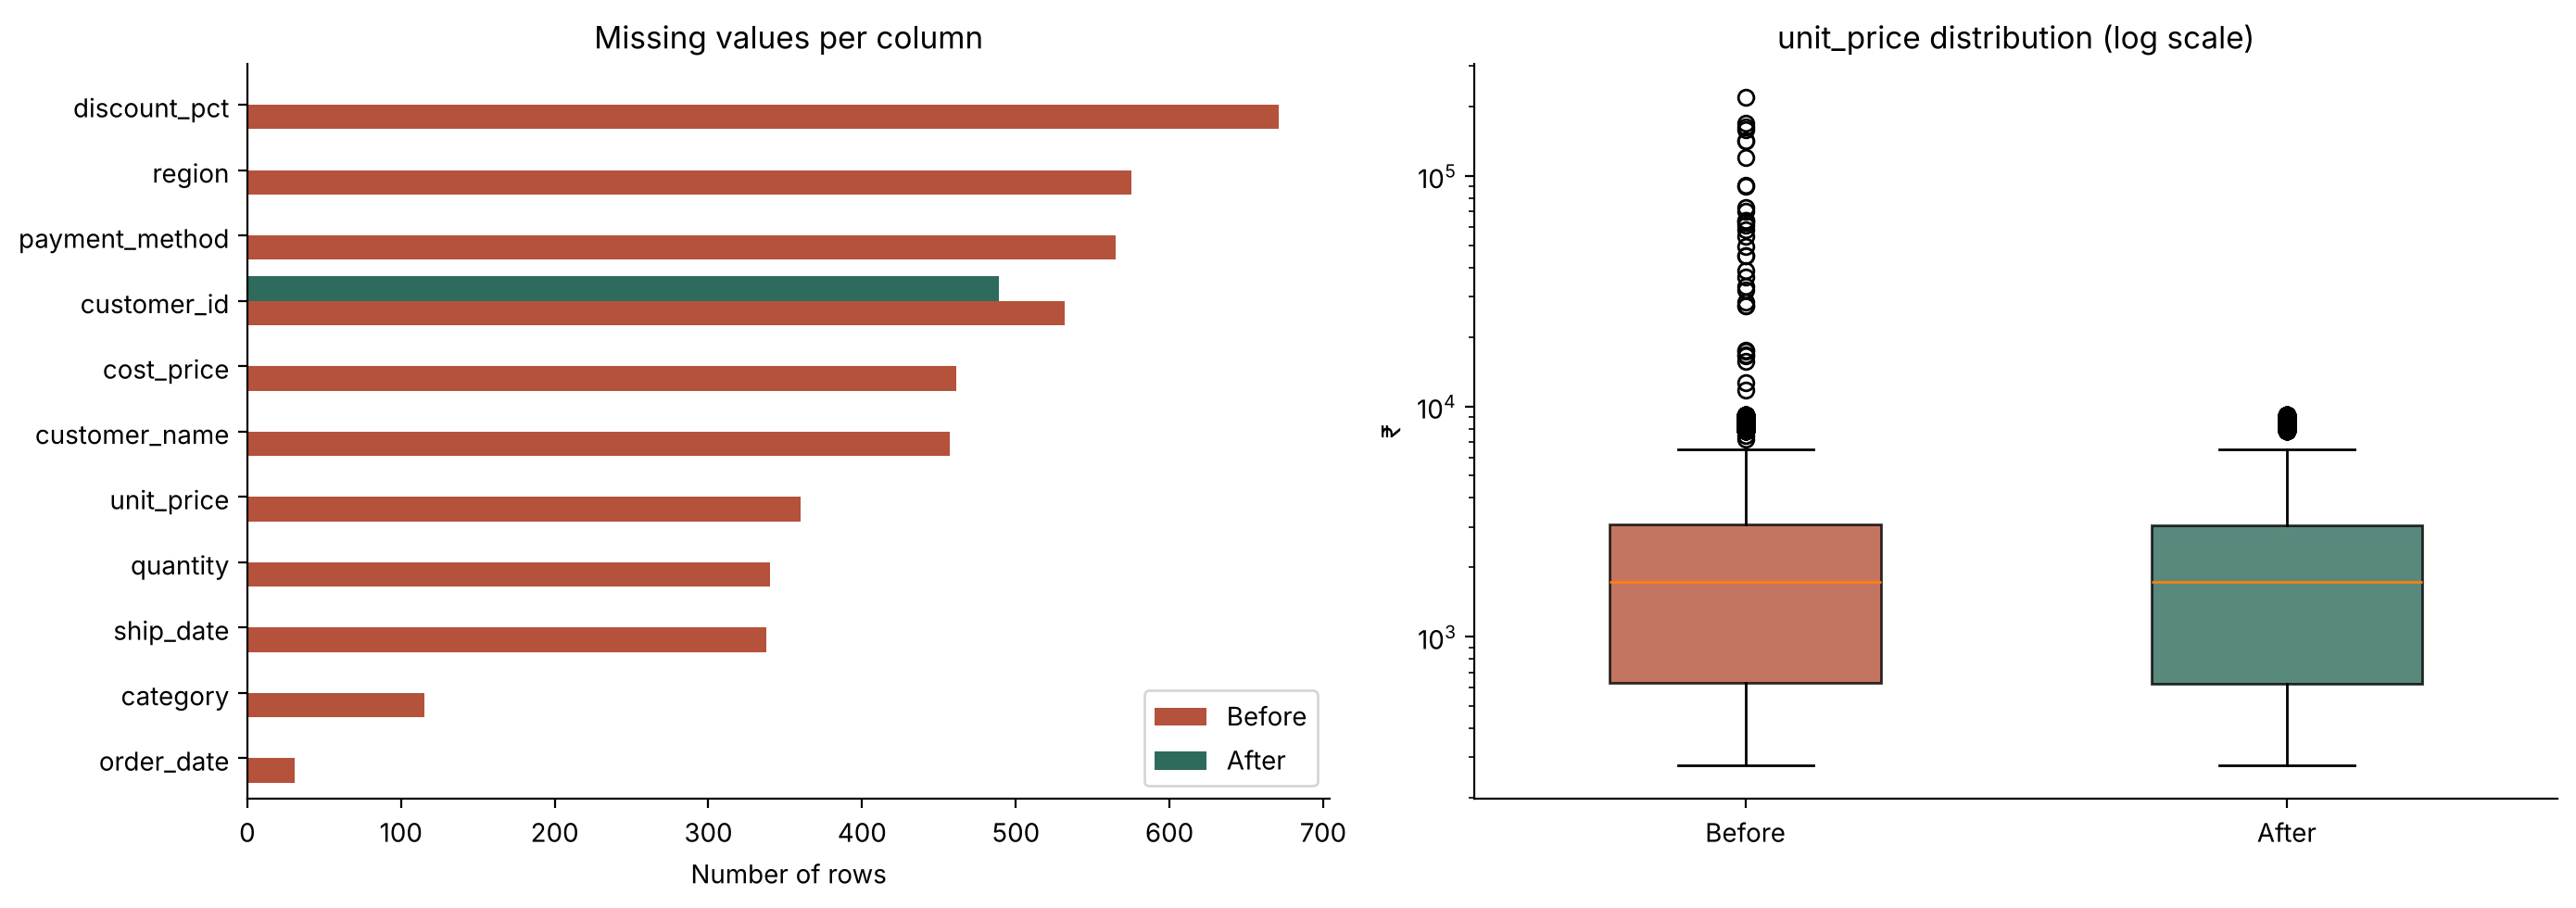

In [15]:
raw_price_numeric = pd.to_numeric(df_raw["unit_price"].astype("string")
                                  .str.replace(r"[₹,]|Rs\.", "", regex=True).str.strip(), errors="coerce")

miss_before = df_raw.isna().sum()
miss_before["order_date"] = parse_mixed_dates(df_raw["order_date"]).isna().sum()   # include placeholder dates
miss = pd.DataFrame({"Before": miss_before, "After": df_clean[orig_cols].isna().sum()})
miss = miss[(miss["Before"] > 0) | (miss["After"] > 0)].sort_values("Before")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
miss.plot.barh(ax=axes[0], color=["#B5523B", "#2F6B5C"], width=0.75)
axes[0].set_title("Missing values per column")
axes[0].set_xlabel("Number of rows")
axes[0].spines[["top", "right"]].set_visible(False)

bp = axes[1].boxplot([raw_price_numeric.dropna(), df_clean["unit_price"]], patch_artist=True, widths=0.5)
for patch, colr in zip(bp["boxes"], ["#B5523B", "#2F6B5C"]):
    patch.set_facecolor(colr); patch.set_alpha(0.8)
axes[1].set_xticks([1, 2], ["Before", "After"])
axes[1].set_yscale("log")
axes[1].set_title("unit_price distribution (log scale)")
axes[1].set_ylabel("₹")
axes[1].spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

In [16]:
print("AFTER - column profile")
profile(df_clean)

AFTER - column profile


,dtype,missing,missing_%,unique
order_id,int64,0,0.00,10469
order_date,datetime64[ns],0,0.00,1095
ship_date,datetime64[ns],0,0.00,1102
customer_id,Int64,489,4.67,2174
customer_name,string,0,0.00,241
region,str,0,0.00,6
category,string,0,0.00,5
product_name,string,0,0.00,25
quantity,int64,0,0.00,7
unit_price,Float64,0,0.00,9913


## 11. Export the clean dataset

In [17]:
df_clean.to_csv("clean_dataset.csv", index=False, date_format="%Y-%m-%d")

check = pd.read_csv("clean_dataset.csv", parse_dates=DATE_COLS)
assert check.shape == df_clean.shape
print(f"Saved clean_dataset.csv: {check.shape[0]:,} rows x {check.shape[1]} columns")
print(f"Raw rows {len(df_raw):,}  ->  clean rows {len(df_clean):,}  ({len(df_raw) - len(df_clean):,} removed: duplicates + unusable dates)")
check.head()

Saved clean_dataset.csv: 10,469 rows x 30 columns
Raw rows 11,300  ->  clean rows 10,469  (831 removed: duplicates + unusable dates)


,order_id,order_date,ship_date,customer_id,customer_name,region,category,product_name,quantity,unit_price,cost_price,discount_pct,payment_method,ship_date_imputed,unit_price_imputed,cost_price_imputed,quantity_imputed,order_year,order_month,month_name,quarter,day_of_week,is_weekend,ship_lag_days,gross_sales,discount_amount,revenue,total_cost,profit,profit_margin_pct
0,102316,2023-01-01,2023-01-04,"1,459.00",Arjun Nair,Central,Clothing,Formal Shirt,5,"1,901.76",977.08,0.00,Credit Card,False,False,False,False,2023,1,January,Q1,Sunday,True,3,"9,508.80",0.00,"9,508.80","4,885.40","4,623.40",48.62
1,103674,2023-01-01,2023-01-06,"2,640.00",Arjun Singh,West,Grocery,Green Tea Box,5,402.87,252.71,5.00,UPI,True,False,False,False,2023,1,January,Q1,Sunday,True,5,"2,014.35",100.72,"1,913.63","1,263.55",650.08,33.97
2,105083,2023-01-01,2023-01-03,"1,045.00",Lakshmi Menon,Central,Clothing,Formal Shirt,5,"1,724.45",919.66,10.00,UPI,False,False,False,False,2023,1,January,Q1,Sunday,True,2,"8,622.25",862.22,"7,760.03","4,598.30","3,161.73",40.74
3,106302,2023-01-01,2023-01-08,"2,108.00",Ravi Patel,East,Home & Kitchen,Water Bottle,3,528.26,214.59,5.00,UPI,False,False,False,False,2023,1,January,Q1,Sunday,True,7,"1,584.78",79.24,"1,505.54",643.77,861.77,57.24
4,107006,2023-01-01,2023-01-03,"2,735.00",Harini Rao,Central,Grocery,Basmati Rice 5kg,3,761.33,582.88,0.00,Cash on Delivery,False,False,False,False,2023,1,January,Q1,Sunday,True,2,"2,283.99",0.00,"2,283.99","1,748.64",535.35,23.44


## Summary of cleaning decisions
- **Standardised** region, category, payment method and customer names (whitespace, casing, abbreviations).
- **Converted** prices, quantities, discounts, customer IDs and 5 mixed date formats into proper numeric and datetime types without losing a single valid value.
- **Removed** exact and near-duplicate orders, after standardisation so that they could be detected.
- **Treated outliers** per product with the IQR rule and re-estimated them with the product median.
- **Imputed** missing values with documented, column-specific rules; `*_imputed` flags keep the estimates traceable. `customer_id` stays blank where unknown.
- **Engineered** 13 features (date parts, shipping lag, revenue, cost, profit, profit margin %).
- **Exported** `clean_dataset.csv`.